# White Volta Flood Forecasting — Version 3
## Calendar-Correct Forecasting + Event-Level LOFO + Flood Difficulty + Explainability

### Main research idea

This version treats a flood **event** rather than an individual day as the main unit of generalization.

The study asks:

> **How well does a flood forecasting model generalize to a completely unseen flood event, and what event characteristics and environmental factors explain differences in forecast difficulty?**

The notebook contains four components:

**A. Calendar-correct forecasting**
- True Q(t+1 day), Q(t+3 days), Q(t+5 days) targets based on dates, not row shifts.

**B. Event-level LOFO**
- One complete flood event is held out.
- Training uses only observations before the held-out event.

**C. Flood-event difficulty analysis**
For each event:
- duration
- peak discharge
- rise rate
- maximum rainfall
- cumulative 3/7/14/30-day rainfall
- soil moisture
- reservoir storage
- antecedent discharge
- forecast MAE/RMSE

**D. Event-level explainability**
- Feature importance for each held-out event.
- Comparison of important features across events.
- Optional SHAP analysis for selected events.

### Important methodological rule

The chronological target is created by merging the observed series with itself by calendar date. Therefore, a 1-day target really means the discharge recorded on the next calendar date, not merely the next available row.

In [8]:

# 1. IMPORTS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score
)
from sklearn.inspection import permutation_importance
from scipy.stats import spearmanr

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

print("Ready.")


Ready.


## 2. Upload `feature_matrix_full.csv`

In [9]:
    
    # 2. LOAD DATA FROM THE LOCAL PROJECT FOLDER
    
    from pathlib import Path
    
    DATA_PATH = Path("..") / "data" / "feature_matrix_full.csv"
    
    if not DATA_PATH.exists():
        raise FileNotFoundError(
            f"CSV not found at {DATA_PATH.resolve()}"
        )
    
    df = pd.read_csv(DATA_PATH)
    df["date"] = pd.to_datetime(df["date"])
    
    print("Data loaded successfully.")
    print("Shape:", df.shape)
    print("Date range:", df["date"].min(), "to", df["date"].max())
    print("Columns:", df.columns.tolist())


Data loaded successfully.
Shape: (13514, 31)
Date range: 1987-01-01 00:00:00 to 2023-12-31 00:00:00
Columns: ['date', 'discharge_grdc', 'rainfall_mm', 'temperature_c', 'et_mm', 'soil_moisture', 'discharge_proxy', 'discharge_proxy_bc', 'discharge', 'bagre_storage', 'bagre_storage_30d', 'discharge_lag1', 'discharge_lag2', 'discharge_lag3', 'discharge_lag4', 'discharge_lag5', 'discharge_lag6', 'discharge_lag7', 'discharge_lag8', 'discharge_lag9', 'discharge_lag10', 'rainfall_lag1', 'rainfall_lag2', 'rainfall_lag3', 'rainfall_lag4', 'rainfall_lag5', 'discharge_3d', 'discharge_7d', 'rainfall_3d', 'rainfall_7d', 'discharge_log']


In [10]:
# ============================================================
# 3. OBSERVED GRDC SERIES + WARNING LEVELS
# ============================================================
YELLOW = 1114.16
ORANGE = 1362.21
RED = 1898.58

obs = df.dropna(subset=["discharge_grdc"]).copy()
obs = obs.sort_values("date").reset_index(drop=True)

def warning_level(q):
    if q < YELLOW:
        return "Normal"
    if q < ORANGE:
        return "Yellow"
    if q < RED:
        return "Orange"
    return "Red"

obs["warning"] = obs["discharge_grdc"].apply(warning_level)

print("Observed GRDC observations:", len(obs))
print("Period:", obs.date.min(), "to", obs.date.max())
print("\nWarning counts:")
display(obs.warning.value_counts())

Observed GRDC observations: 7251
Period: 1987-01-01 00:00:00 to 2007-02-28 00:00:00

Warning counts:


warning
Normal    6740
Orange     264
Red        128
Yellow     119
Name: count, dtype: int64

# A. CALENDAR-CORRECT FORECAST TARGETS

Instead of:

```python
shift(-1)
```

we use date-based lookup.

For every observation on date `t`:

```text
target_1d = discharge on t + 1 calendar day
target_3d = discharge on t + 3 calendar days
target_5d = discharge on t + 5 calendar days
```

If the required future calendar date is missing, that row is not used for that horizon.

In [11]:
# ============================================================
# 4. TRUE CALENDAR-DAY TARGETS
# ============================================================
daily = obs.set_index("date").sort_index()

for h in [1, 3, 5]:
    target_map = daily["discharge_grdc"].copy()
    target_map.index = target_map.index - pd.to_timedelta(h, unit="D")
    obs[f"target_{h}d"] = obs["date"].map(target_map)

print("Target availability:")
for h in [1,3,5]:
    print(f"{h}-day:", obs[f"target_{h}d"].notna().sum(), "rows")

Target availability:
1-day: 7237 rows
3-day: 7223 rows
5-day: 7214 rows


# B. FLOOD EVENT DETECTION

A new event begins when discharge reaches the Yellow threshold after at least two consecutive below-threshold days.

The event definition is an analytical grouping rule used to prevent correlated days from being split across train/test.

In [12]:
# ============================================================
# 5. DETECT FLOOD EVENTS
# ============================================================
flag = obs.discharge_grdc >= YELLOW

episode=[]
eid=0
below=2

for x in flag:
    if x:
        if below >= 2:
            eid += 1
        episode.append(eid)
        below=0
    else:
        episode.append(0)
        below += 1

obs["episode_id"]=episode

events=[]
for e,g in obs[obs.episode_id>0].groupby("episode_id"):
    events.append({
        "episode_id":int(e),
        "start":g.date.min(),
        "end":g.date.max(),
        "duration_days":len(g),
        "peak_discharge":g.discharge_grdc.max(),
        "peak_date":g.loc[g.discharge_grdc.idxmax(),"date"]
    })

events=pd.DataFrame(events)

print("Detected flood events:",len(events))
display(events)

Detected flood events: 13


,episode_id,start,end,duration_days,peak_discharge,peak_date
0,1,1987-09-04,1987-09-18,14,1386.983,1987-09-13
1,2,1988-08-29,1988-10-09,42,1823.170,1988-09-30
2,3,1989-08-18,1989-10-19,63,2240.794,1989-09-14
3,4,1991-08-15,1991-09-29,45,2200.747,1991-09-08
4,5,1993-08-30,1993-09-28,30,1973.621,1993-09-25
5,6,1994-08-25,1994-10-21,58,2279.335,1994-10-15
6,7,1995-08-17,1995-09-19,34,1528.535,1995-09-06
7,8,1996-09-07,1996-10-15,39,1622.740,1996-09-27
8,9,1998-09-23,1998-10-14,22,1602.343,1998-10-04
9,10,1999-08-12,1999-10-22,72,2274.140,1999-09-18


# C. EVENT CHARACTERISTICS

For each flood event we calculate antecedent conditions at the event start.

These features describe the event before or at its onset, so they can later be related to forecasting difficulty without using future event information.

In [7]:
# ============================================================
# 6. EVENT CHARACTERISTICS
# ============================================================
# Work on the complete date-indexed observed series.
s = obs.set_index("date").sort_index()

event_rows=[]

for _,ev in events.iterrows():
    start=ev["start"]
    end=ev["end"]

    # Event rows
    eg=s.loc[start:end].copy()

    # Previous 1 day discharge (antecedent discharge)
    prev1=s.loc[s.index < start].tail(1)["discharge_grdc"]
    antecedent_q=float(prev1.iloc[0]) if len(prev1) else np.nan

    # Rainfall windows BEFORE event start
    rain_features={}
    for days in [3,7,14,30]:
        prior=s.loc[(s.index < start) & (s.index >= start-pd.Timedelta(days=days))]
        rain_features[f"rainfall_cum_{days}d"]=prior["rainfall_mm"].sum(min_count=1)

    # Rainfall during the event
    event_rain=eg["rainfall_mm"]

    # Rise rate: maximum positive daily change in discharge during
    # the event, normalized as m3/s per day.
    dq=eg["discharge_grdc"].diff()
    rise_rate=dq.max()

    # Soil moisture and reservoir storage around event onset
    onset_window=s.loc[
        (s.index >= start-pd.Timedelta(days=3)) &
        (s.index <= start)
    ]

    row={
        "episode_id":int(ev.episode_id),
        "start":start,
        "end":end,
        "duration_days":int(ev.duration_days),
        "peak_discharge":ev.peak_discharge,
        "peak_date":ev.peak_date,
        "rise_rate_m3s_per_day":rise_rate,
        "max_rainfall_event":event_rain.max(),
        "soil_moisture_onset":onset_window["soil_moisture"].mean(),
        "reservoir_storage_onset":onset_window["bagre_storage"].mean(),
        "antecedent_discharge":antecedent_q
    }
    row.update(rain_features)
    event_rows.append(row)

event_characteristics=pd.DataFrame(event_rows)

display(event_characteristics)
event_characteristics.to_csv("event_characteristics.csv",index=False)

,episode_id,start,end,duration_days,peak_discharge,peak_date,rise_rate_m3s_per_day,max_rainfall_event,soil_moisture_onset,reservoir_storage_onset,antecedent_discharge,rainfall_cum_3d,rainfall_cum_7d,rainfall_cum_14d,rainfall_cum_30d
0,1,1987-09-04,1987-09-18,14,1386.983,1987-09-13,378.937,18.440053,0.314762,0.000000,1093.512,12.637161,49.757054,102.672032,217.950331
1,2,1988-08-29,1988-10-09,42,1823.170,1988-09-30,89.711,27.119956,0.403916,0.443958,1025.026,51.790190,85.088676,131.996657,212.485592
2,3,1989-08-18,1989-10-19,63,2240.794,1989-09-14,220.174,22.188364,0.374439,0.338864,1075.966,15.774491,53.728554,116.432887,206.312660
3,4,1991-08-15,1991-09-29,45,2200.747,1991-09-08,108.466,16.042884,0.370527,0.000000,1103.064,27.559197,77.761325,124.604513,216.130872
4,5,1993-08-30,1993-09-28,30,1973.621,1993-09-25,511.884,16.381781,0.348000,0.000000,1111.843,18.193637,47.166013,99.981512,201.688655
5,6,1994-08-25,1994-10-21,58,2279.335,1994-10-15,812.642,28.042217,0.384476,0.103696,1085.506,37.913817,54.282430,108.859466,204.362690
6,7,1995-08-17,1995-09-19,34,1528.535,1995-09-06,40.337,18.351942,0.368257,0.465932,1093.504,33.442932,56.984951,131.883117,213.392091
7,8,1996-09-07,1996-10-15,39,1622.740,1996-09-27,58.314,16.387256,0.351319,0.000000,1106.588,28.404986,57.869642,104.983266,215.775754
8,9,1998-09-23,1998-10-14,22,1602.343,1998-10-04,103.880,9.105245,0.376342,0.000000,1100.092,19.258965,57.718231,107.308140,198.153359
9,10,1999-08-12,1999-10-22,72,2274.140,1999-09-18,133.072,21.203074,0.382247,0.000000,1082.450,27.416417,45.693020,89.439668,197.347019


# D. LEAKAGE-CONTROLLED FORECAST FEATURES

Only information available at forecast time is used.

Included:
- current environmental observations
- historical discharge lags
- historical rainfall lags
- seasonal variables

Excluded:
- current/future target discharge
- reconstructed/proxy discharge
- warning label
- event ID
- future event characteristics

In [13]:
# ============================================================
# 7. MODEL FEATURES
# ============================================================
candidate_features=[
    "rainfall_mm",
    "temperature_c",
    "et_mm",
    "soil_moisture",
    "bagre_storage",
    "bagre_storage_30d",
    "discharge_lag1",
    "discharge_lag2",
    "discharge_lag3",
    "discharge_lag4",
    "discharge_lag5",
    "discharge_lag6",
    "discharge_lag7",
    "discharge_lag8",
    "discharge_lag9",
    "discharge_lag10",
    "rainfall_lag1",
    "rainfall_lag2",
    "rainfall_lag3",
    "rainfall_lag4",
    "rainfall_lag5",
]

features=[c for c in candidate_features if c in obs.columns]

obs["sin_doy"]=np.sin(2*np.pi*obs.date.dt.dayofyear/365.25)
obs["cos_doy"]=np.cos(2*np.pi*obs.date.dt.dayofyear/365.25)

features += ["sin_doy","cos_doy"]

model_df=obs.copy()

print("Number of features:",len(features))
print(features)

Number of features: 23
['rainfall_mm', 'temperature_c', 'et_mm', 'soil_moisture', 'bagre_storage', 'bagre_storage_30d', 'discharge_lag1', 'discharge_lag2', 'discharge_lag3', 'discharge_lag4', 'discharge_lag5', 'discharge_lag6', 'discharge_lag7', 'discharge_lag8', 'discharge_lag9', 'discharge_lag10', 'rainfall_lag1', 'rainfall_lag2', 'rainfall_lag3', 'rainfall_lag4', 'rainfall_lag5', 'sin_doy', 'cos_doy']


# E. STRICT TEMPORAL LOFO

For each flood event:

- Test = the complete held-out flood event.
- Training = observations before the beginning of that event.
- No observations from the held-out event enter training.
- No observations after the held-out event enter training.

This makes the evaluation deliberately conservative.

In [14]:
# ============================================================
# 8. LOFO FORECASTING FUNCTION
# ============================================================
event_ids=sorted(events.episode_id.tolist())

def warning(q):
    if q < YELLOW: return "Normal"
    if q < ORANGE: return "Yellow"
    if q < RED: return "Orange"
    return "Red"

def run_lofo(horizon, n_estimators=300):
    target=f"target_{horizon}d"
    work=model_df.dropna(subset=[target]).copy()

    folds=[]
    predictions=[]

    for eid in event_ids:
        test=work[work.episode_id==eid].copy()
        if len(test)==0:
            continue

        start=test.date.min()

        # Strict temporal development set
        train=work[work.date<start].copy()

        if len(train)<300:
            continue

        Xtr=train[features].copy()
        Xte=test[features].copy()
        ytr=train[target].values
        yte=test[target].values

        # Train-only imputation
        med=Xtr.median()
        Xtr=Xtr.fillna(med)
        Xte=Xte.fillna(med)

        model=RandomForestRegressor(
            n_estimators=n_estimators,
            random_state=42,
            n_jobs=-1,
            max_features="sqrt",
            min_samples_leaf=2
        )

        model.fit(Xtr,ytr)
        pred=model.predict(Xte)

        folds.append({
            "horizon_days":horizon,
            "episode_id":eid,
            "test_start":test.date.min(),
            "test_end":test.date.max(),
            "n_test":len(test),
            "MAE":mean_absolute_error(yte,pred),
            "RMSE":np.sqrt(mean_squared_error(yte,pred)),
            "R2":r2_score(yte,pred) if len(np.unique(yte))>1 else np.nan,
            "warning_accuracy":accuracy_score(
                [warning(x) for x in yte],
                [warning(x) for x in pred]
            )
        })

        p=test[["date","episode_id","discharge_grdc"]].copy()
        p["horizon_days"]=horizon
        p["actual_future_discharge"]=yte
        p["predicted_discharge"]=pred
        p["absolute_error"]=np.abs(yte-pred)
        p["actual_warning"]=[warning(x) for x in yte]
        p["predicted_warning"]=[warning(x) for x in pred]
        predictions.append(p)

    return pd.DataFrame(folds),pd.concat(predictions,ignore_index=True)

folds=[]
preds=[]

for h in [1,3,5]:
    print("\n"+"="*70)
    print(f"{h}-DAY CALENDAR-CORRECT LOFO")
    print("="*70)

    f,p=run_lofo(h)
    display(f)
    folds.append(f)
    preds.append(p)

fold_results=pd.concat(folds,ignore_index=True)
predictions=pd.concat(preds,ignore_index=True)

summary=fold_results.groupby("horizon_days").agg(
    mean_MAE=("MAE","mean"),
    median_MAE=("MAE","median"),
    std_MAE=("MAE","std"),
    mean_RMSE=("RMSE","mean"),
    mean_R2=("R2","mean"),
    mean_warning_accuracy=("warning_accuracy","mean"),
    events=("episode_id","nunique")
).reset_index()

display(summary)


1-DAY CALENDAR-CORRECT LOFO


,horizon_days,episode_id,test_start,test_end,n_test,MAE,RMSE,R2,warning_accuracy
0,1,2,1988-08-29,1988-10-09,42,422.141026,488.496721,-5.819134,0.142857
1,1,3,1989-08-18,1989-10-19,63,507.321480,561.849249,-2.104819,0.126984
2,1,4,1991-08-15,1991-09-29,44,178.963364,228.812405,0.476698,0.545455
3,1,5,1993-08-30,1993-09-28,30,128.189130,168.711826,0.513141,0.700000
4,1,6,1994-08-25,1994-10-21,58,135.997078,189.449627,0.575308,0.568966
5,1,7,1995-08-17,1995-09-19,34,100.003846,107.298511,0.373953,0.823529
6,1,8,1996-09-07,1996-10-15,39,49.178714,58.097303,0.852001,0.897436
7,1,9,1998-09-23,1998-10-14,22,102.308513,119.647306,0.435909,0.681818
8,1,10,1999-08-12,1999-10-22,72,72.053184,87.452050,0.919765,0.875000
9,1,11,2001-09-05,2001-10-05,31,74.185370,98.426845,0.822196,0.870968



3-DAY CALENDAR-CORRECT LOFO


,horizon_days,episode_id,test_start,test_end,n_test,MAE,RMSE,R2,warning_accuracy
0,3,2,1988-08-29,1988-10-09,42,496.163932,581.101486,-6.538003,0.190476
1,3,3,1989-08-18,1989-10-19,63,626.790150,671.230964,-2.703983,0.063492
2,3,4,1991-08-15,1991-09-29,44,241.780607,290.929207,0.302282,0.454545
3,3,5,1993-08-30,1993-09-28,30,176.461723,215.211201,0.318817,0.766667
4,3,6,1994-08-25,1994-10-21,58,174.512756,226.586109,0.507126,0.448276
5,3,7,1995-08-17,1995-09-19,34,152.656260,168.135325,-0.113856,0.705882
6,3,8,1996-09-07,1996-10-15,39,105.634944,119.391247,0.537228,0.743590
7,3,9,1998-09-23,1998-10-14,22,148.197869,170.978934,0.393154,0.636364
8,3,10,1999-08-12,1999-10-22,72,98.332429,116.648236,0.874654,0.833333
9,3,11,2001-09-05,2001-10-05,31,124.156791,162.824306,0.691293,0.903226



5-DAY CALENDAR-CORRECT LOFO


,horizon_days,episode_id,test_start,test_end,n_test,MAE,RMSE,R2,warning_accuracy
0,5,2,1988-08-29,1988-10-09,42,560.556603,658.641868,-4.802469,0.238095
1,5,3,1989-08-18,1989-10-19,63,690.730310,732.523613,-2.177536,0.079365
2,5,4,1991-08-15,1991-09-29,44,312.370419,365.818688,0.187976,0.340909
3,5,5,1993-08-30,1993-09-28,30,208.539351,259.975326,0.218730,0.533333
4,5,6,1994-08-25,1994-10-21,58,196.546205,243.724656,0.547714,0.379310
5,5,7,1995-08-17,1995-09-19,34,192.768572,222.137884,-0.258569,0.676471
6,5,8,1996-09-07,1996-10-15,39,185.976466,205.848887,0.071337,0.538462
7,5,9,1998-09-23,1998-10-14,22,215.693776,241.387663,0.325849,0.500000
8,5,10,1999-08-12,1999-10-22,72,112.770458,133.800424,0.865886,0.777778
9,5,11,2001-09-05,2001-10-05,31,192.091786,230.096325,0.625404,0.774194


,horizon_days,mean_MAE,median_MAE,std_MAE,mean_RMSE,mean_R2,mean_warning_accuracy,events
0,1,160.559170,101.156179,147.406148,191.284169,-0.735160,0.651607,12
1,3,217.388446,153.792171,167.713545,254.480256,-0.954260,0.569507,12
2,5,270.248137,202.542778,175.976536,312.889863,-0.782161,0.483715,12


# F. EVENT DIFFICULTY

For each event and horizon we calculate forecast error.

Then we merge the error with event characteristics.

This creates the core research dataset:

> **Event characteristics → forecasting difficulty**

We can then test whether difficult events are associated with particular hydrological/environmental conditions.

In [17]:
# ============================================================
# 9. MERGE EVENT DIFFICULTY DATA
# ============================================================
event_perf=fold_results.merge(
    event_characteristics,
    on="episode_id",
    how="left"
)

display(event_perf)

event_perf.to_csv("event_level_performance_v3.csv",index=False)

NameError: name 'event_characteristics' is not defined

## Correlation screening

Because the number of flood events is small, we use **Spearman rank correlation** as an exploratory analysis rather than claiming causal relationships.

The purpose is to identify variables worth discussing and testing further.

In [11]:
# ============================================================
# 10. EVENT DIFFICULTY CORRELATIONS
# ============================================================
difficulty_vars=[
    "duration_days",
    "peak_discharge",
    "rise_rate_m3s_per_day",
    "max_rainfall_event",
    "rainfall_cum_3d",
    "rainfall_cum_7d",
    "rainfall_cum_14d",
    "rainfall_cum_30d",
    "soil_moisture_onset",
    "reservoir_storage_onset",
    "antecedent_discharge"
]

corr_rows=[]

for h in [1,3,5]:
    sub=event_perf[event_perf.horizon_days==h]

    for v in difficulty_vars:
        x=sub[v]
        y=sub["MAE"]

        valid=x.notna() & y.notna()

        if valid.sum()>=5 and x[valid].nunique()>1:
            rho,p=spearmanr(x[valid],y[valid])
        else:
            rho,p=np.nan,np.nan

        corr_rows.append({
            "horizon_days":h,
            "variable":v,
            "spearman_rho":rho,
            "p_value":p,
            "n_events":valid.sum()
        })

difficulty_corr=pd.DataFrame(corr_rows)

display(
    difficulty_corr.sort_values(
        ["horizon_days","spearman_rho"],
        ascending=[True,False]
    )
)

difficulty_corr.to_csv("event_difficulty_correlations.csv",index=False)

,horizon_days,variable,spearman_rho,p_value,n_events
6,1,rainfall_cum_14d,0.629371,0.028320,12
5,1,rainfall_cum_7d,0.461538,0.130948,12
8,1,soil_moisture_onset,0.461538,0.130948,12
4,1,rainfall_cum_3d,0.293706,0.354148,12
2,1,rise_rate_m3s_per_day,0.286713,0.366251,12
1,1,peak_discharge,0.279720,0.378569,12
3,1,max_rainfall_event,0.230769,0.470532,12
7,1,rainfall_cum_30d,0.216783,0.498556,12
9,1,reservoir_storage_onset,0.174027,0.588559,12
0,1,duration_days,0.160839,0.617523,12


# G. VISUALIZE EVENT DIFFICULTY

The following figures are designed to answer simple questions such as:

- Do larger peak discharges correspond to larger forecast errors?
- Does rapid discharge rise make prediction harder?
- Does antecedent rainfall relate to forecasting difficulty?
- Does the relationship change with forecast horizon?

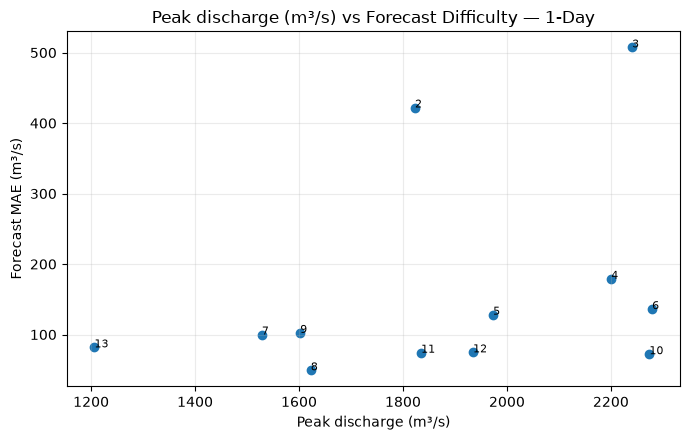

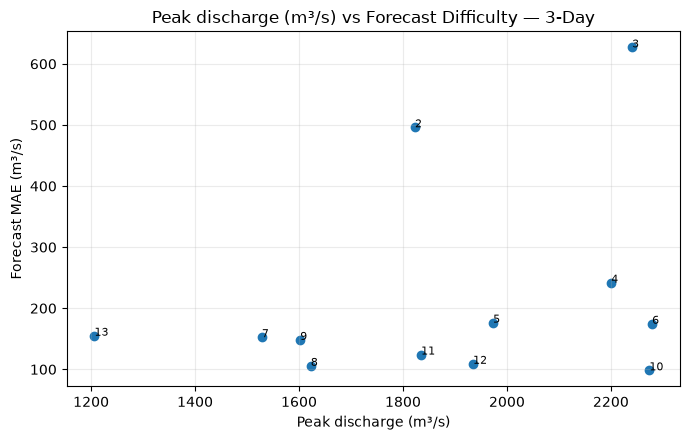

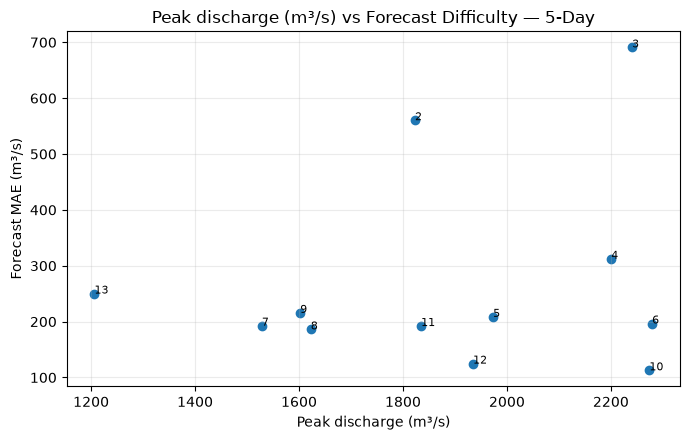

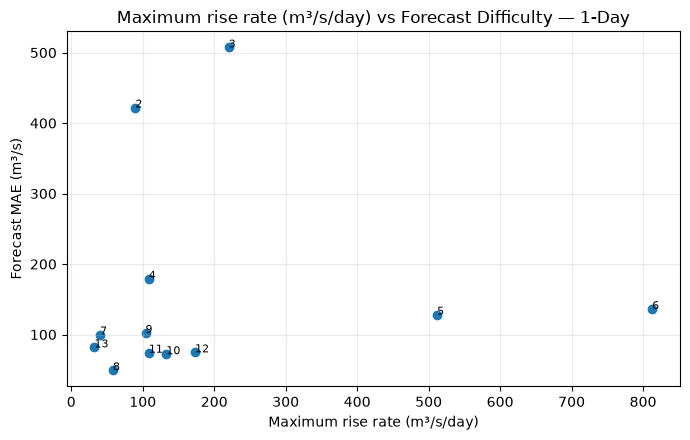

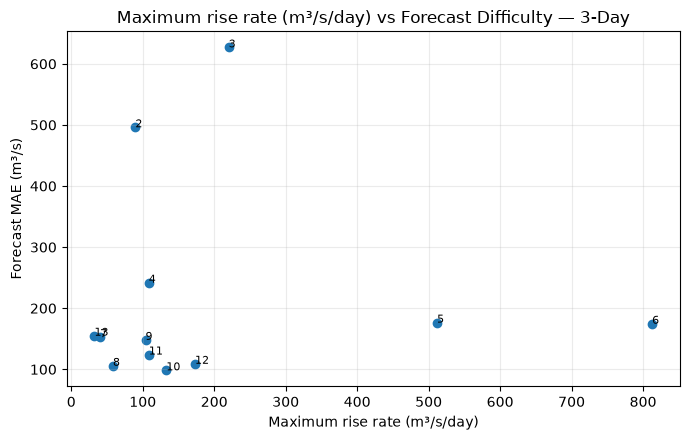

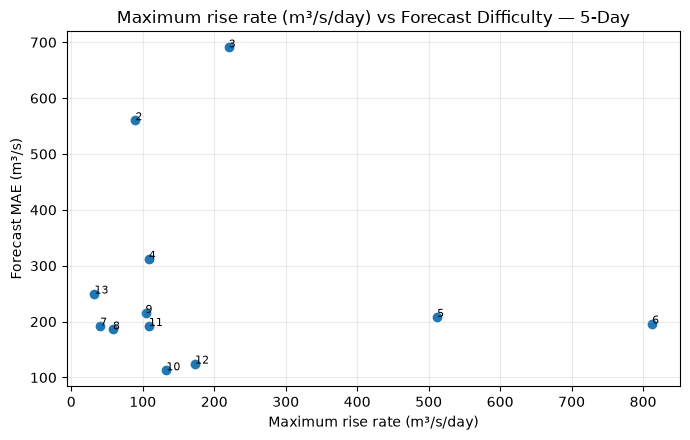

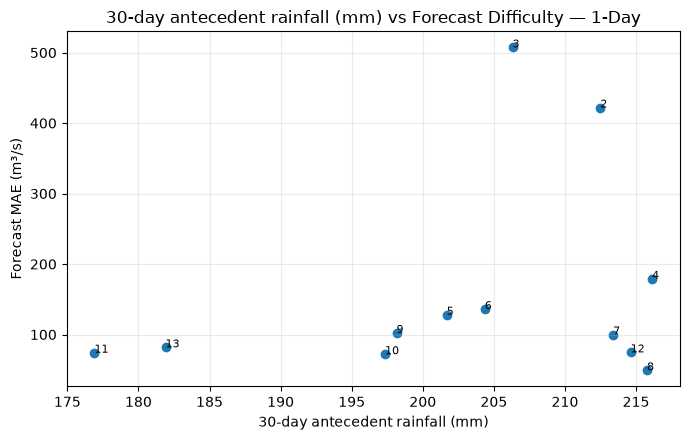

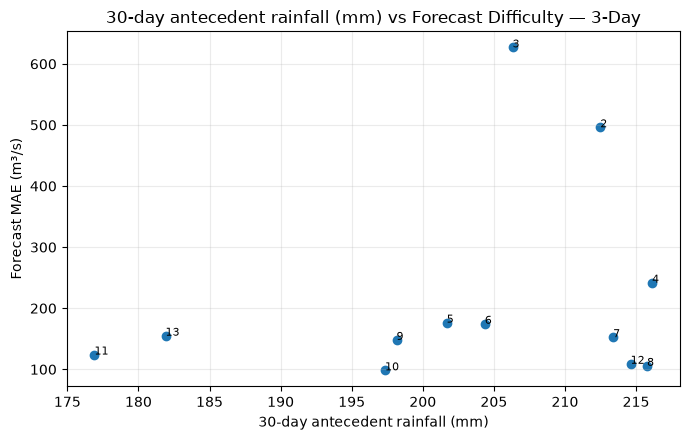

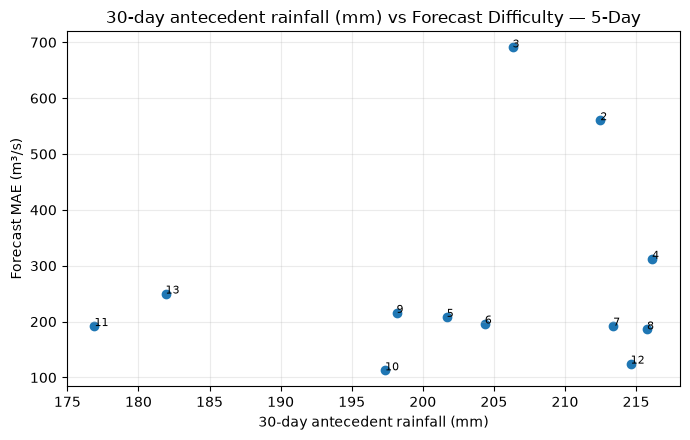

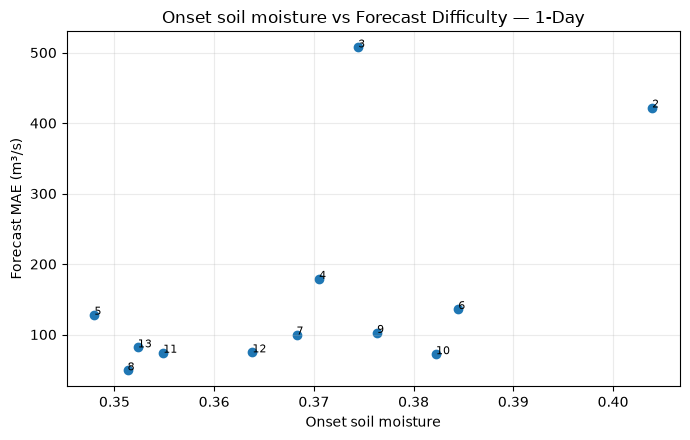

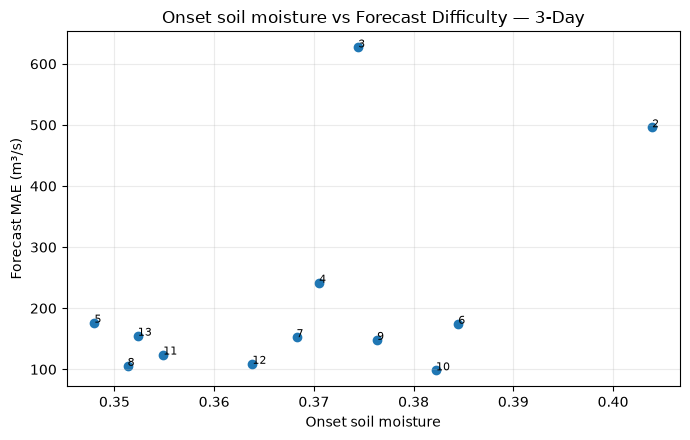

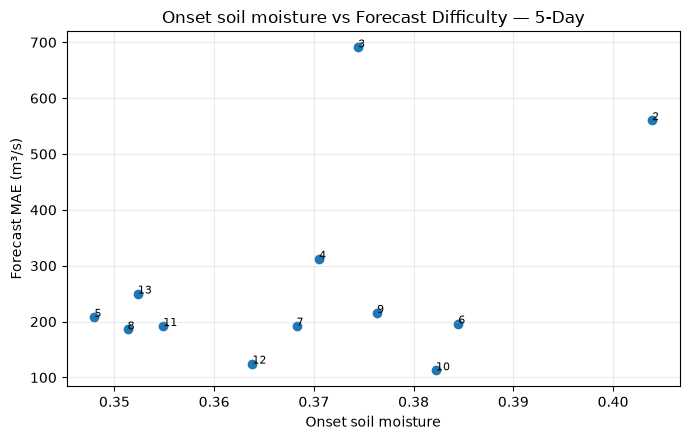

In [13]:
# ============================================================
# 11. EVENT DIFFICULTY SCATTER PLOTS
# ============================================================
plot_vars=[
    ("peak_discharge","Peak discharge (m³/s)"),
    ("rise_rate_m3s_per_day","Maximum rise rate (m³/s/day)"),
    ("rainfall_cum_30d","30-day antecedent rainfall (mm)"),
    ("soil_moisture_onset","Onset soil moisture")
]

for var,label in plot_vars:
    for h in [1,3,5]:
        sub=event_perf[event_perf.horizon_days==h].dropna(subset=[var,"MAE"])

        plt.figure(figsize=(7,4.5))
        plt.scatter(sub[var],sub["MAE"])
        for _,r in sub.iterrows():
            plt.annotate(
                str(int(r.episode_id)),
                (r[var],r["MAE"]),
                fontsize=8
            )
        plt.xlabel(label)
        plt.ylabel("Forecast MAE (m³/s)")
        plt.title(f"{label} vs Forecast Difficulty — {h}-Day")
        plt.grid(True,alpha=.25)
        plt.tight_layout()
        plt.show()

# H. EVENT-LEVEL EXPLAINABILITY

A global feature-importance plot tells us what the model generally uses.

Here we go one step further:

> **Does the model rely on the same predictors for every flood event?**

For each held-out event, permutation importance is calculated on that event's test observations.

A feature is considered locally important when shuffling it increases test MAE.

This is an event-level explanation of model behavior, not a causal claim.

In [15]:
# ============================================================
# 12. EVENT-LEVEL PERMUTATION IMPORTANCE
# ============================================================
importance_rows=[]

def event_importance(horizon, n_estimators=300):
    target=f"target_{horizon}d"
    work=model_df.dropna(subset=[target]).copy()

    for eid in event_ids:
        test=work[work.episode_id==eid].copy()
        if len(test)<5:
            continue

        start=test.date.min()
        train=work[work.date<start].copy()

        if len(train)<300:
            continue

        Xtr=train[features].copy()
        Xte=test[features].copy()
        ytr=train[target].values
        yte=test[target].values

        med=Xtr.median()
        Xtr=Xtr.fillna(med)
        Xte=Xte.fillna(med)

        model=RandomForestRegressor(
            n_estimators=n_estimators,
            random_state=42,
            n_jobs=-1,
            max_features="sqrt",
            min_samples_leaf=2
        )
        model.fit(Xtr,ytr)

        pi=permutation_importance(
            model,
            Xte,
            yte,
            scoring="neg_mean_absolute_error",
            n_repeats=5,
            random_state=42,
            n_jobs=-1
        )

        for feature,imp,std in zip(
            features,
            pi.importances_mean,
            pi.importances_std
        ):
            importance_rows.append({
                "horizon_days":horizon,
                "episode_id":eid,
                "feature":feature,
                "importance":imp,
                "importance_std":std
            })

for h in [1,3,5]:
    print("Explainability:",h,"day")
    event_importance(h)

event_importance_df=pd.DataFrame(importance_rows)

display(
    event_importance_df.sort_values(
        ["horizon_days","episode_id","importance"],
        ascending=[True,True,False]
    ).groupby(["horizon_days","episode_id"]).head(5)
)

event_importance_df.to_csv(
    "event_level_feature_importance.csv",
    index=False
)

Explainability: 1 day
Explainability: 3 day
Explainability: 5 day


,horizon_days,episode_id,feature,importance,importance_std
11,1,2,discharge_lag6,2.027358,0.232344
5,1,2,bagre_storage_30d,1.988420,0.459360
22,1,2,cos_doy,1.383910,0.398316
21,1,2,sin_doy,1.202579,0.486059
9,1,2,discharge_lag4,1.153666,0.120045
...,...,...,...,...,...
806,5,13,temperature_c,4.636765,7.886175
808,5,13,soil_moisture,3.063599,5.677763
823,5,13,rainfall_lag3,2.321420,2.252093
807,5,13,et_mm,1.846129,1.682448


# I. TOP FEATURES BY EVENT

This figure shows the top five features for each flood event.

The research question is:

> **Is the forecasting model using the same information for every flood event, or does its reasoning change from event to event?**

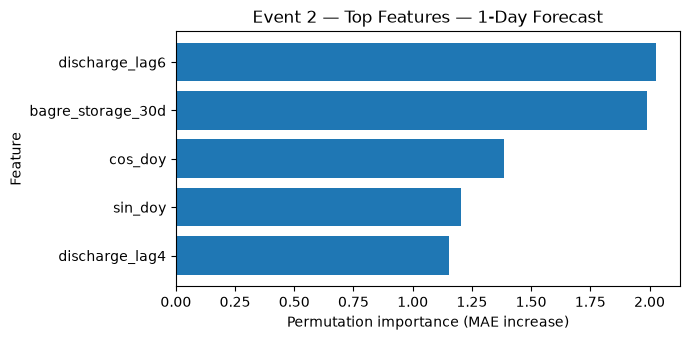

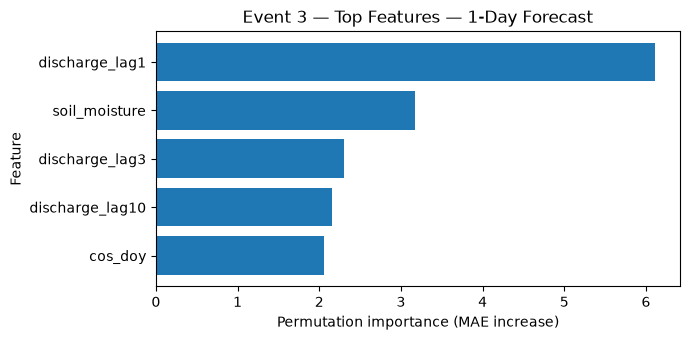

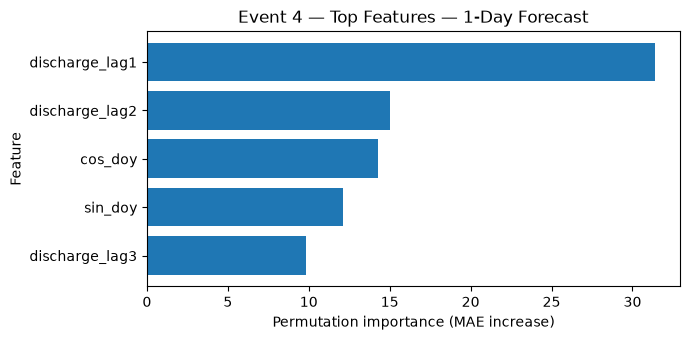

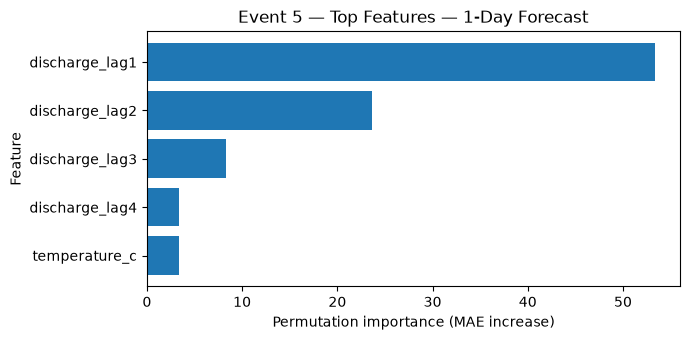

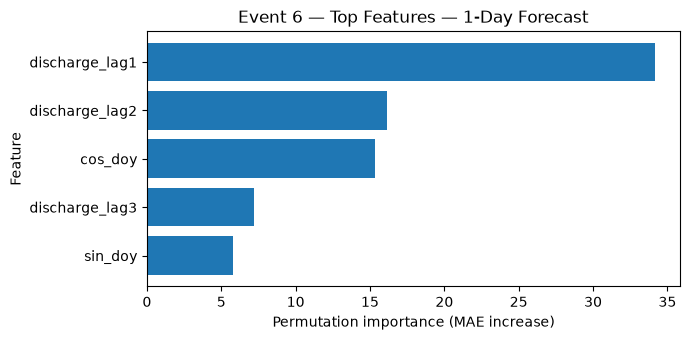

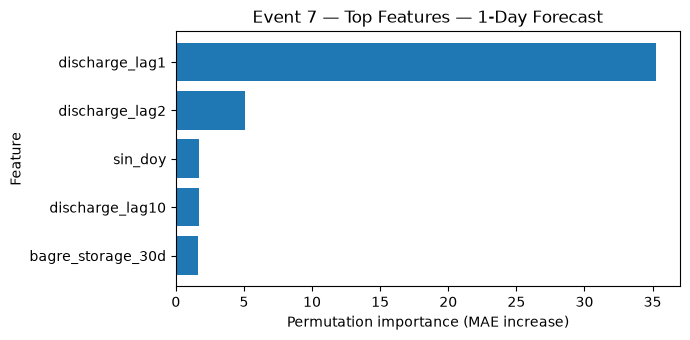

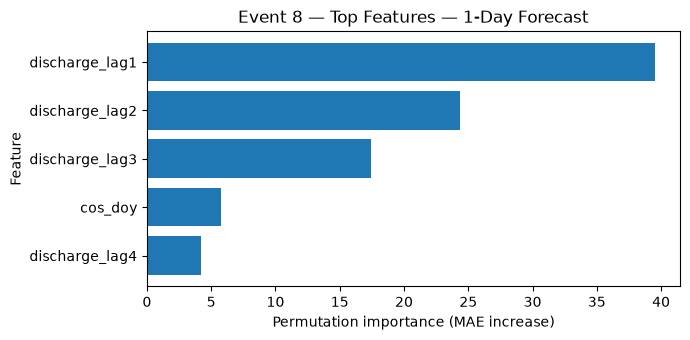

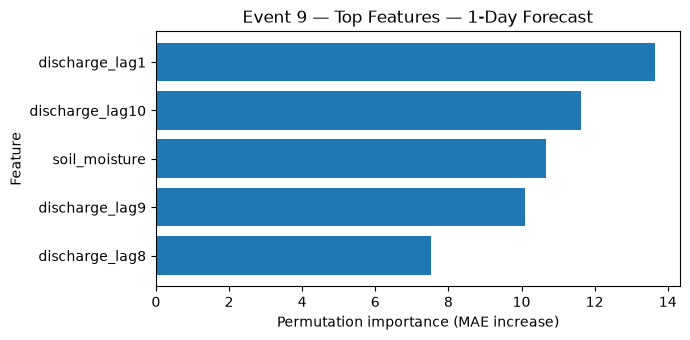

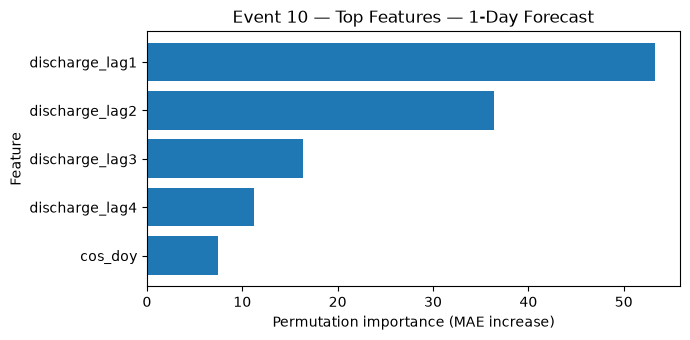

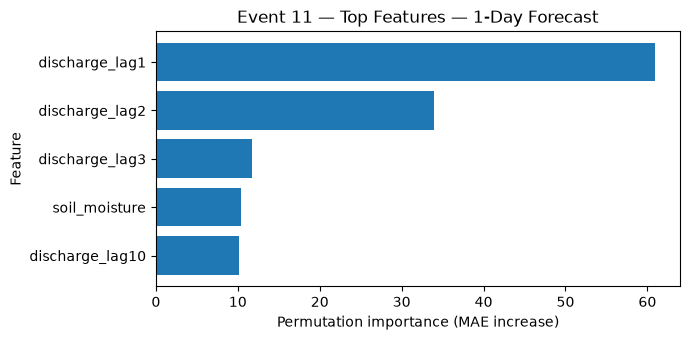

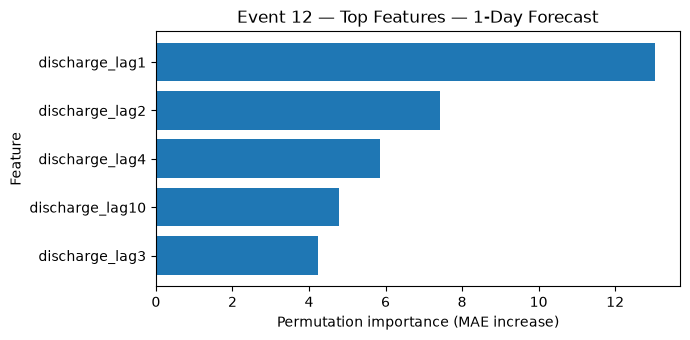

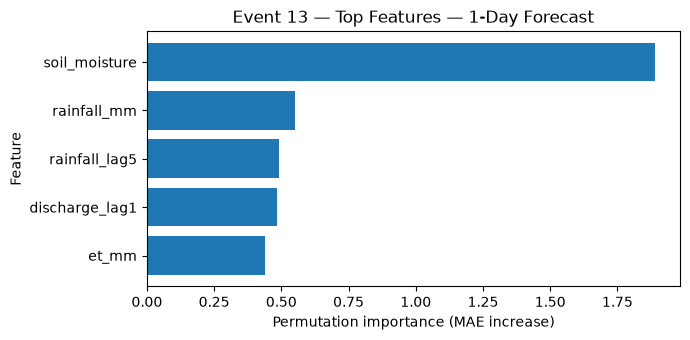

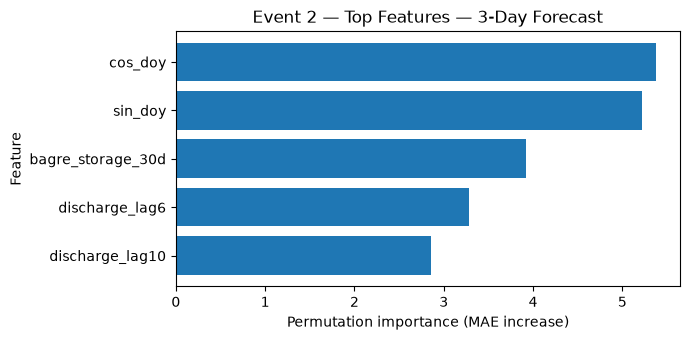

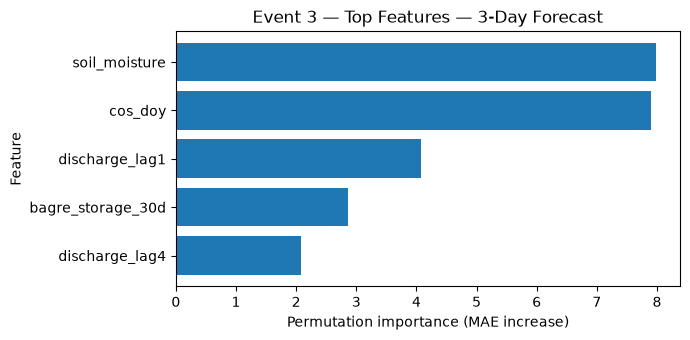

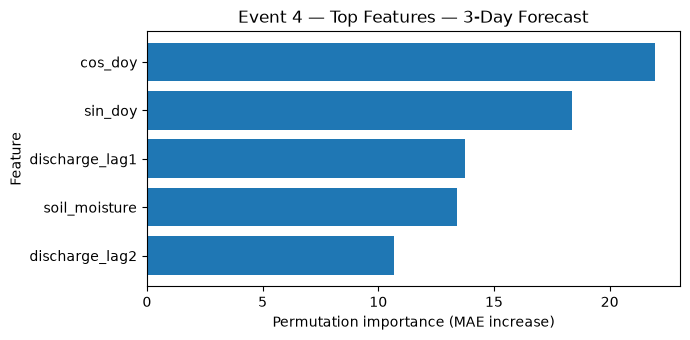

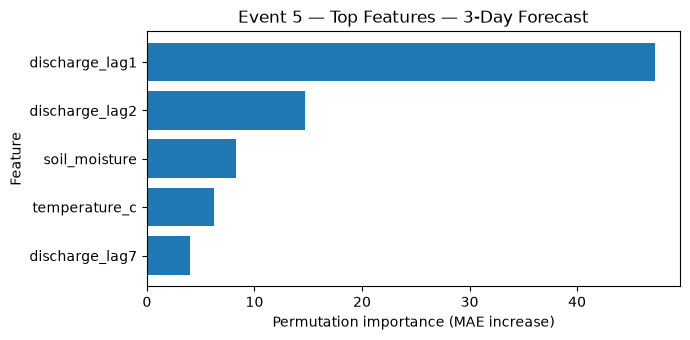

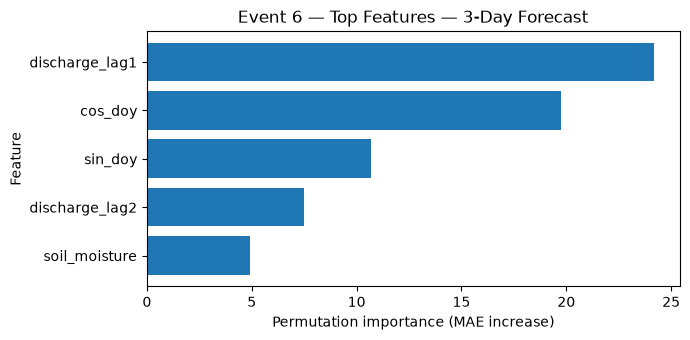

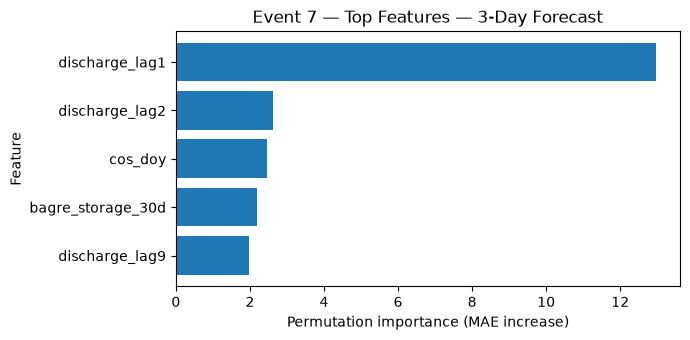

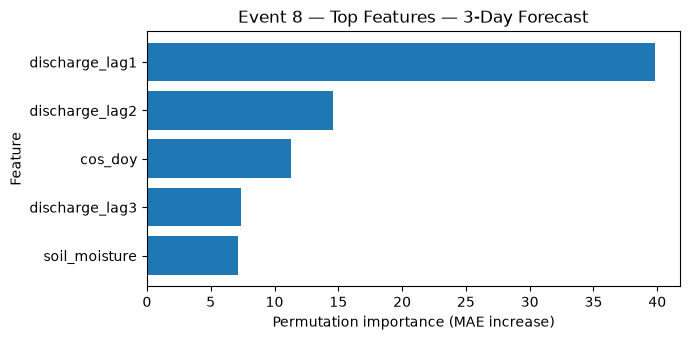

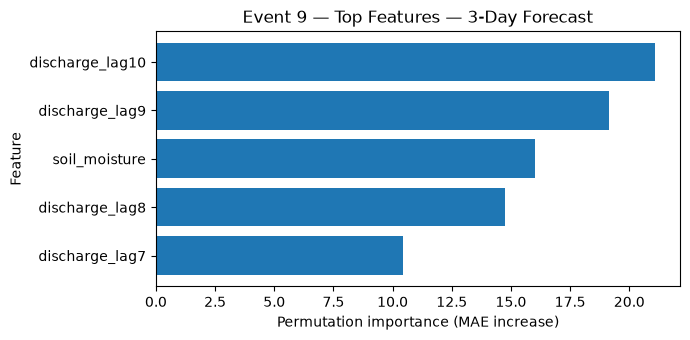

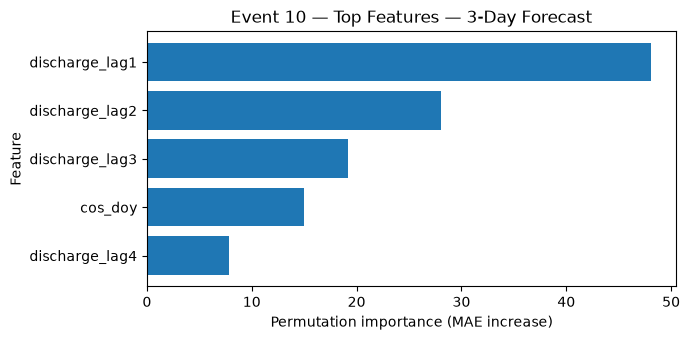

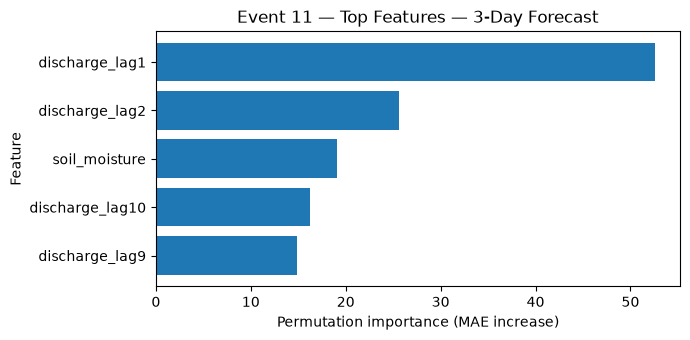

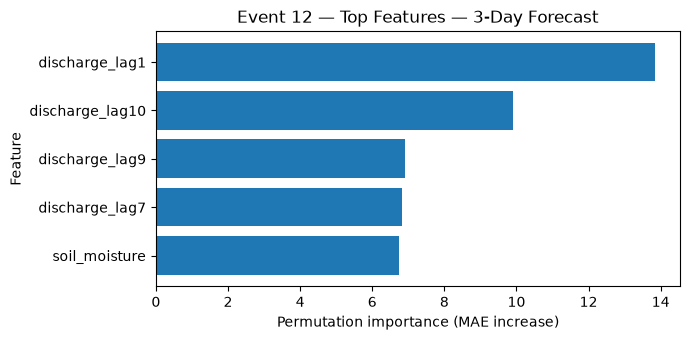

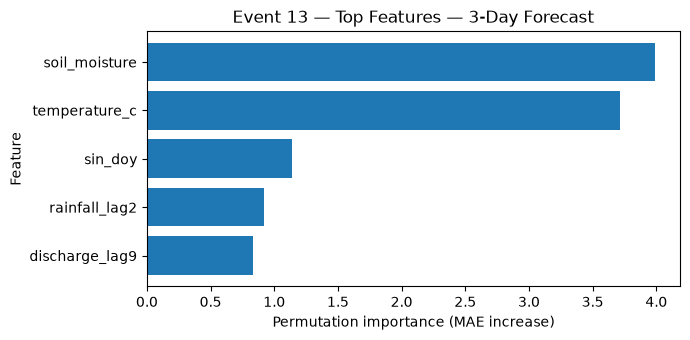

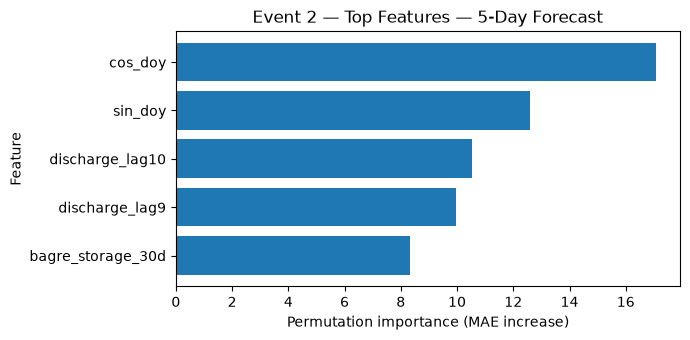

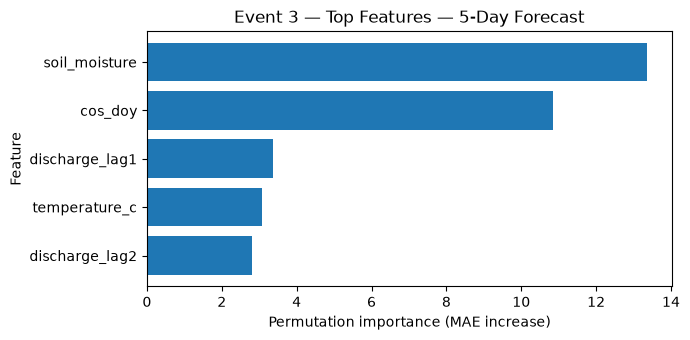

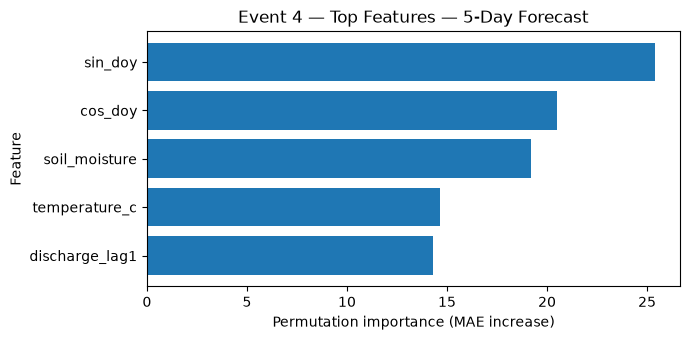

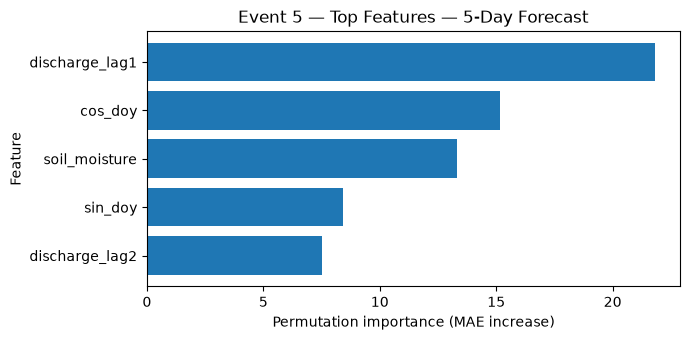

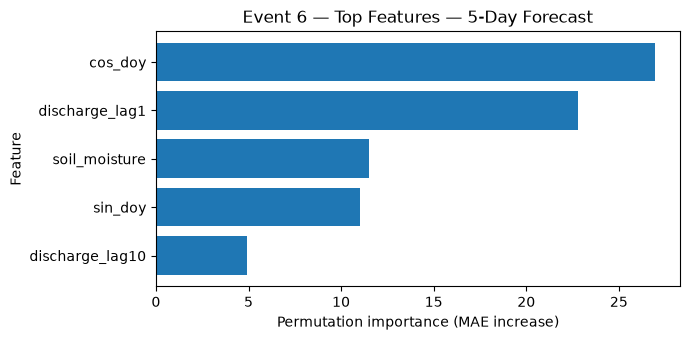

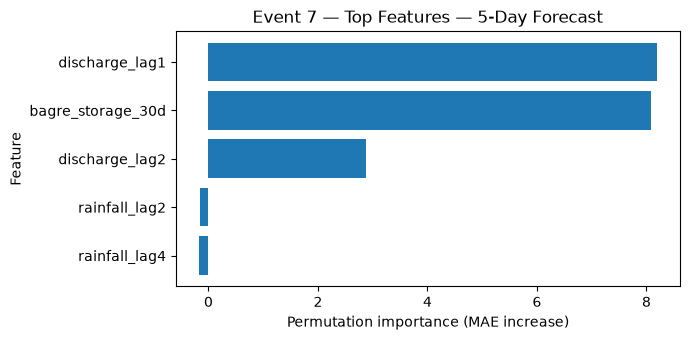

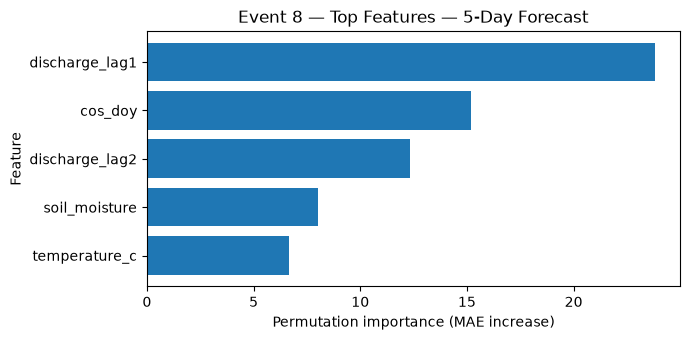

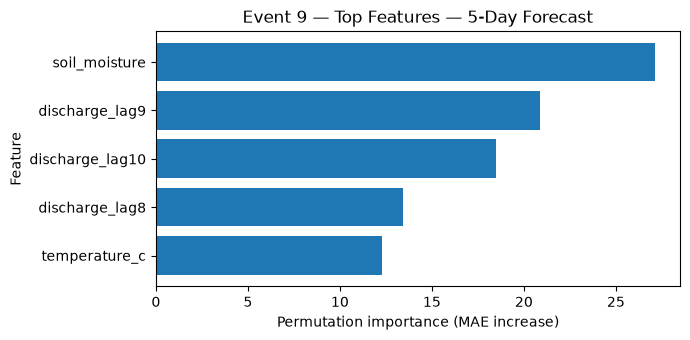

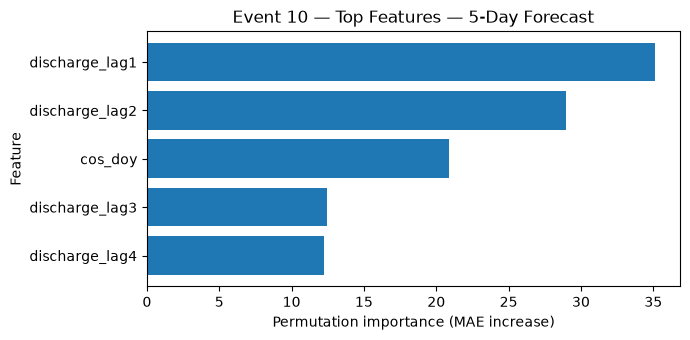

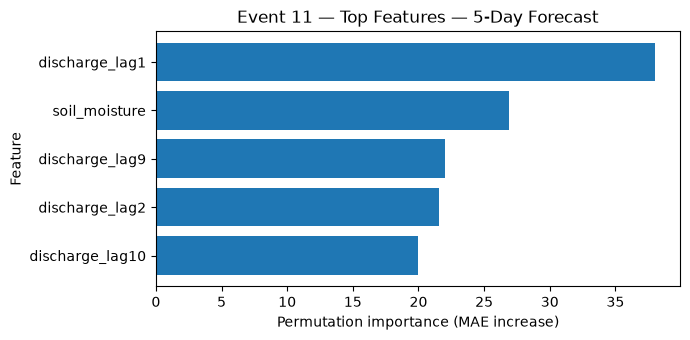

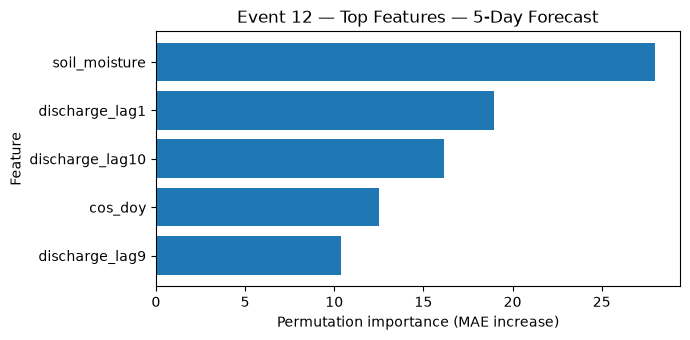

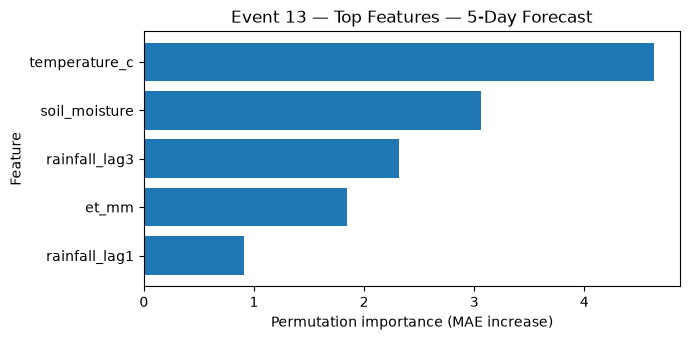

In [16]:
# ============================================================
# 13. EVENT-LEVEL TOP FEATURES
# ============================================================
for h in [1,3,5]:
    sub=event_importance_df[event_importance_df.horizon_days==h]

    for eid in sorted(sub.episode_id.unique()):
        top=sub[sub.episode_id==eid].nlargest(5,"importance").sort_values("importance")

        plt.figure(figsize=(7,3.5))
        plt.barh(top.feature,top.importance)
        plt.xlabel("Permutation importance (MAE increase)")
        plt.ylabel("Feature")
        plt.title(f"Event {eid} — Top Features — {h}-Day Forecast")
        plt.tight_layout()
        plt.show()

# J. EVENT-TO-EVENT EXPLAINABILITY STABILITY

We summarize how frequently each feature appears among the top-5 important features across held-out flood events.

This provides a simple measure of **explanation stability**.

In [17]:
# ============================================================
# 14. EXPLANATION STABILITY
# ============================================================
stability=[]

for h in [1,3,5]:
    sub=event_importance_df[event_importance_df.horizon_days==h]

    for eid in sub.episode_id.unique():
        top=set(
            sub[sub.episode_id==eid]
            .nlargest(5,"importance")
            .feature
        )

        for f in features:
            stability.append({
                "horizon_days":h,
                "episode_id":eid,
                "feature":f,
                "in_top5":int(f in top)
            })

stability_df=pd.DataFrame(stability)

stability_summary=(
    stability_df.groupby(["horizon_days","feature"])
    .agg(
        events=("episode_id","nunique"),
        top5_count=("in_top5","sum"),
        top5_rate=("in_top5","mean")
    )
    .reset_index()
    .sort_values(
        ["horizon_days","top5_rate"],
        ascending=[True,False]
    )
)

display(stability_summary.groupby("horizon_days").head(15))

stability_summary.to_csv(
    "explanation_stability.csv",
    index=False
)

,horizon_days,feature,events,top5_count,top5_rate
3,1,discharge_lag1,12,11,0.916667
5,1,discharge_lag2,12,8,0.666667
6,1,discharge_lag3,12,8,0.666667
2,1,cos_doy,12,6,0.500000
4,1,discharge_lag10,12,5,0.416667
7,1,discharge_lag4,12,5,0.416667
20,1,sin_doy,12,4,0.333333
21,1,soil_moisture,12,4,0.333333
1,1,bagre_storage_30d,12,2,0.166667
9,1,discharge_lag6,12,1,0.083333


# K. OPTIONAL SHAP ANALYSIS

Permutation importance is the primary explainability method because it is computationally lighter and easy to compare across events.

If desired, this section performs SHAP on one selected event/horizon.

SHAP should be used as a complementary explanation rather than the main novelty.

In [3]:
# ============================================================
# 15. OPTIONAL SHAP — SELECT ONE EVENT
# ============================================================
import shap

SELECT_EVENT = int(event_ids[-1])
SELECT_HORIZON = 1

target=f"target_{SELECT_HORIZON}d"
work=model_df.dropna(subset=[target]).copy()

test=work[work.episode_id==SELECT_EVENT].copy()
train=work[work.date<test.date.min()].copy()

Xtr=train[features].copy()
Xte=test[features].copy()
ytr=train[target].values

med=Xtr.median()
Xtr=Xtr.fillna(med)
Xte=Xte.fillna(med)

shap_model=RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1,
    max_features="sqrt",
    min_samples_leaf=2
)
shap_model.fit(Xtr,ytr)

# Limit explanation sample for speed
sample=Xte.sample(min(500,len(Xte)),random_state=42)

explainer=shap.TreeExplainer(shap_model)
sv=explainer.shap_values(sample)

shap.summary_plot(
    sv,
    sample,
    plot_type="bar",
    show=True
)

shap.summary_plot(
    sv,
    sample,
    show=True
)

NameError: name 'event_ids' is not defined

# L. FINAL RESEARCH TABLES

The main outputs are:

1. `event_characteristics.csv`
2. `event_level_performance_v3.csv`
3. `event_difficulty_correlations.csv`
4. `event_level_feature_importance.csv`
5. `explanation_stability.csv`

### Possible paper storyline

**Problem**
Daily random train/test splits can overestimate flood-forecast performance because neighboring observations within a flood episode are correlated.

**Evaluation**
Use calendar-correct 1-, 3-, and 5-day targets and leave one entire flood event out for testing.

**Analysis**
Measure not only average prediction error, but also how error varies from event to event.

**Interpretability**
Explain which environmental and hydrological variables the model uses for each unseen event.

**Novel analysis**
Relate event characteristics to forecast difficulty and examine whether model explanations remain stable across flood episodes.

The study should describe correlation results as exploratory because the number of flood events is small.

In [16]:
# ============================================================
# 16. SAVE + ZIP ALL RESULTS
# ============================================================
import os, shutil

fold_results.to_csv("LOFO_calendar_correct_fold_results.csv",index=False)
predictions.to_csv("LOFO_calendar_correct_predictions.csv",index=False)
summary.to_csv("LOFO_calendar_correct_summary.csv",index=False)

output_files=[
    "event_characteristics.csv",
    "LOFO_calendar_correct_fold_results.csv",
    "LOFO_calendar_correct_predictions.csv",
    "LOFO_calendar_correct_summary.csv",
    "event_level_performance_v3.csv",
    "event_difficulty_correlations.csv",
    "event_level_feature_importance.csv",
    "explanation_stability.csv"
]

existing=[x for x in output_files if os.path.exists(x)]

with open("README_V3_results.txt","w") as f:
    f.write("White Volta Version 3 Results\n")
    f.write("Calendar-correct forecasting + event LOFO + event difficulty + explainability.\n\n")
    for x in existing:
        f.write(x+"\n")

shutil.make_archive(
    "White_Volta_V3_Results",
    "zip",
    root_dir=".",
    base_dir="."
)

print("Created White_Volta_V3_Results.zip")
print("\nFiles:")
for x in existing:
    print(" -",x)


    

Created White_Volta_V3_Results.zip

Files:
 - event_characteristics.csv
 - LOFO_calendar_correct_fold_results.csv
 - LOFO_calendar_correct_predictions.csv
 - LOFO_calendar_correct_summary.csv
 - event_level_performance_v3.csv
 - event_difficulty_correlations.csv
 - event_level_feature_importance.csv
 - explanation_stability.csv


In [20]:

from pathlib import Path

required_files = [
    "event_characteristics.csv",
    "LOFO_calendar_correct_fold_results.csv",
    "LOFO_calendar_correct_predictions.csv",
    "LOFO_calendar_correct_summary.csv",
    "event_level_performance_v3.csv",
    "event_difficulty_correlations.csv",
    "event_level_feature_importance.csv",
    "explanation_stability.csv",
]

for filename in required_files:
    path = Path(filename)
    print(f"{'FOUND' if path.exists() else 'MISSING'}: {filename}")


FOUND: event_characteristics.csv
MISSING: LOFO_calendar_correct_fold_results.csv
MISSING: LOFO_calendar_correct_predictions.csv
MISSING: LOFO_calendar_correct_summary.csv
FOUND: event_level_performance_v3.csv
FOUND: event_difficulty_correlations.csv
FOUND: event_level_feature_importance.csv
FOUND: explanation_stability.csv


In [21]:

for name in ["fold_results", "predictions", "summary"]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: available, type={type(obj).__name__}")
        if hasattr(obj, "shape"):
            print(f"  shape={obj.shape}")
    else:
        print(f"{name}: NOT AVAILABLE")


fold_results: available, type=DataFrame
  shape=(36, 9)
predictions: available, type=DataFrame
  shape=(1488, 9)
summary: available, type=DataFrame
  shape=(3, 8)


In [22]:

fold_results.to_csv("LOFO_calendar_correct_fold_results.csv", index=False)
predictions.to_csv("LOFO_calendar_correct_predictions.csv", index=False)
summary.to_csv("LOFO_calendar_correct_summary.csv", index=False)

print("Saved fold results:", fold_results.shape)
print("Saved predictions:", predictions.shape)
print("Saved summary:", summary.shape)


Saved fold results: (36, 9)
Saved predictions: (1488, 9)
Saved summary: (3, 8)


In [23]:

from pathlib import Path

required_files = [
    "event_characteristics.csv",
    "LOFO_calendar_correct_fold_results.csv",
    "LOFO_calendar_correct_predictions.csv",
    "LOFO_calendar_correct_summary.csv",
    "event_level_performance_v3.csv",
    "event_difficulty_correlations.csv",
    "event_level_feature_importance.csv",
    "explanation_stability.csv",
]

for filename in required_files:
    path = Path(filename)
    if path.exists():
        print(f"FOUND: {filename} ({path.stat().st_size:,} bytes)")
    else:
        print(f"MISSING: {filename}")


FOUND: event_characteristics.csv (2,748 bytes)
FOUND: LOFO_calendar_correct_fold_results.csv (3,800 bytes)
FOUND: LOFO_calendar_correct_predictions.csv (124,801 bytes)
FOUND: LOFO_calendar_correct_summary.csv (447 bytes)
FOUND: event_level_performance_v3.csv (10,891 bytes)
FOUND: event_difficulty_correlations.csv (2,150 bytes)
FOUND: event_level_feature_importance.csv (47,361 bytes)
FOUND: explanation_stability.csv (2,453 bytes)


In [24]:

from pathlib import Path
import zipfile

required_files = [
    "event_characteristics.csv",
    "LOFO_calendar_correct_fold_results.csv",
    "LOFO_calendar_correct_predictions.csv",
    "LOFO_calendar_correct_summary.csv",
    "event_level_performance_v3.csv",
    "event_difficulty_correlations.csv",
    "event_level_feature_importance.csv",
    "explanation_stability.csv",
]

missing = [f for f in required_files if not Path(f).is_file()]

if missing:
    print("ZIP NOT CREATED. Missing files:", missing)
else:
    zip_path = Path("White_Volta_V3_Results.zip")
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
        for filename in required_files:
            zf.write(filename, arcname=filename)

    print("Created:", zip_path.resolve())
    print("Files packaged:", len(required_files))
    print("ZIP size:", f"{zip_path.stat().st_size:,} bytes")


Created: C:\Users\negia\FloodWatch\ml\notebooks\White_Volta_V3_Results.zip
Files packaged: 8
ZIP size: 70,830 bytes


In [1]:
import shap
print("SHAP version:", shap.__version__)
print("SHAP import successful.")

C:\Users\negia\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP version: 0.53.0
SHAP import successful.


In [18]:
print("obs exists:", "obs" in globals())
print("events exists:", "events" in globals())

obs exists: True
events exists: True


In [ ]:

from pathlib import Path
import zipfile

result_files = [
    "event_characteristics.csv",
    "LOFO_calendar_correct_fold_results.csv",
    "LOFO_calendar_correct_predictions.csv",
    "LOFO_calendar_correct_summary.csv",
    "event_level_performance_v3.csv",
    "event_difficulty_correlations.csv",
    "event_level_feature_importance.csv",
    "explanation_stability.csv",
]

zip_path = Path("White_Volta_V3_Results.zip")

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for filename in result_files:
        path = Path(filename)
        if not path.is_file() or path.stat().st_size == 0:
            raise FileNotFoundError(
                f"Missing or empty result file: {filename}"
            )
        zf.write(path, arcname=filename)

with zipfile.ZipFile(zip_path, "r") as zf:
    packaged = zf.namelist()
    bad_file = zf.testzip()

print("ZIP created:", zip_path.resolve())
print("Files packaged:", len(packaged))
print("Integrity check:", "PASS" if bad_file is None else f"FAIL: {bad_file}")
print("Contents:")
for filename in packaged:
    print("-", filename)
